# Step 06: Data Augmentation & Feature Scaling Experiments

This notebook provides a multi-run benchmark (`NUM_RUNS = 3`) to test **Data Augmentation and Feature Scaling techniques** for mmWave radar fall detection under 3-Fold Leave-One-Subject-Out (LOSO) cross-validation.

### Testing Workflow:
1. **Baseline**: Evaluates standard model without augmentation.
2. **All Combined**: Evaluates all data augmentation and scaling techniques applied together.
3. **Individual Ablation**: Evaluates each data augmentation/scaling technique individually to isolate its specific impact on Accuracy, Macro F1, and ROC-AUC.


In [14]:
# Cell 1: System Imports & Setup
%load_ext autoreload
%autoreload 2
import sys
import json
from pathlib import Path
root_dir = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(root_dir) not in sys.path: sys.path.insert(0, str(root_dir))

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.models import ResNet18Adaptor, PointNetPlusPlusFallDetector, Radar4DCNN, get_model_summary
from src.train_loso import run_loso_cross_validation

sns.set_theme(style="whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch Device: {device}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch Device: cpu


In [15]:
# Cell 2: Select Representation & Multi-Run Hyperparameters
REPRESENTATION = "rep3"  # Standard default representation
NUM_RUNS = 3             # Standard 3 distinct random seeds (42, 52, 62)
EPOCHS = 15
LR = 5e-4
BATCH_SIZE = 32

print(f"Selected Representation: '{REPRESENTATION}' | NUM_RUNS: {NUM_RUNS} | Epochs: {EPOCHS} | LR: {LR}")


Selected Representation: 'rep3' | NUM_RUNS: 3 | Epochs: 15 | LR: 0.0005


In [16]:
# Cell 3: Define Augmentation & Scaling Functions

def aug_lateral_flip(x: torch.Tensor) -> torch.Tensor:
    """1. Lateral Flip: Randomly flips width axis with 50% probability."""
    if torch.rand(1).item() > 0.5:
        if x.dim() == 4:
            x = torch.flip(x, dims=[3])
        elif x.dim() == 3:
            x = x.clone()
            x[:, 1, :] = -x[:, 1, :]
            if x.size(1) >= 4: x[:, 3, :] = -x[:, 3, :]
    return x

def aug_xy_rotation(x: torch.Tensor, max_deg: float = 30.0) -> torch.Tensor:
    """2. X-Y Rotation: Rotates around vertical Z-axis (-30 to +30 deg)."""
    angle_rad = np.radians(np.random.uniform(-max_deg, max_deg))
    cos_a, sin_a = float(np.cos(angle_rad)), float(np.sin(angle_rad))
    x_aug = x.clone()
    if x.dim() == 3 and x.size(1) >= 2:
        x_orig, y_orig = x_aug[:, 0, :].clone(), x_aug[:, 1, :].clone()
        x_aug[:, 0, :] = cos_a * x_orig - sin_a * y_orig
        x_aug[:, 1, :] = sin_a * x_orig + cos_a * y_orig
    return x_aug

def aug_distance_scaling(x: torch.Tensor, scale_range: tuple = (0.90, 1.10)) -> torch.Tensor:
    """3. Distance Scaling: Rescales spatial coordinates by factor (0.90 to 1.10)."""
    scale = float(np.random.uniform(scale_range[0], scale_range[1]))
    x_aug = x.clone()
    if x.dim() == 3 and x.size(1) >= 3:
        x_aug[:, 0:3, :] = x_aug[:, 0:3, :] * scale
    else:
        x_aug = x_aug * scale
    return x_aug

def aug_velocity_scaling(x: torch.Tensor, scale_range: tuple = (0.90, 1.10)) -> torch.Tensor:
    """4. Velocity Scaling: Rescales Doppler velocity feature by (0.90 to 1.10)."""
    scale = float(np.random.uniform(scale_range[0], scale_range[1]))
    x_aug = x.clone()
    if x.dim() == 3 and x.size(1) >= 4:
        x_aug[:, 3, :] = x_aug[:, 3, :] * scale
    elif x.dim() == 4 and x.size(1) >= 2:
        x_aug[:, 1, :, :] = x_aug[:, 1, :, :] * scale
    return x_aug

def aug_snr_scaling(x: torch.Tensor, scale_range: tuple = (0.85, 1.15)) -> torch.Tensor:
    """5. SNR / Intensity Scaling: Rescales reflection intensity channel (0.85 to 1.15)."""
    scale = float(np.random.uniform(scale_range[0], scale_range[1]))
    x_aug = x.clone()
    if x.dim() == 3 and x.size(1) >= 5:
        x_aug[:, 4, :] = torch.clamp(x_aug[:, 4, :] * scale, min=0.0)
    elif x.dim() == 4:
        x_aug[:, -1, :, :] = torch.clamp(x_aug[:, -1, :, :] * scale, min=0.0)
    return x_aug

def aug_spatial_jitter(x: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    """6. Spatial Jitter: Adds Gaussian noise (std=0.02)."""
    noise = torch.randn_like(x) * std
    return x + noise

def aug_all_combined(x: torch.Tensor) -> torch.Tensor:
    """Combines all 6 data augmentation and scaling transformations."""
    x = aug_lateral_flip(x)
    x = aug_xy_rotation(x)
    x = aug_distance_scaling(x)
    x = aug_velocity_scaling(x)
    x = aug_snr_scaling(x)
    x = aug_spatial_jitter(x)
    return x

print("All augmentation & scaling functions compiled successfully.")


All augmentation & scaling functions compiled successfully.


In [17]:
# Cell 4: Execute Multi-Run (NUM_RUNS = 3) Baseline vs All Combined Evaluation
print(f"\n--- 1. Evaluating Baseline Model (No Augmentation, {NUM_RUNS} Runs) on '{REPRESENTATION}' ---")
res_baseline = run_loso_cross_validation(
    rep_key=REPRESENTATION,
    epochs=EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    num_runs=NUM_RUNS,
    save_benchmark=False
)
m_base = res_baseline["test_metrics"]

print(f"\n--- 2. Evaluating All Combined Augmentations & Scalings ({NUM_RUNS} Runs) on '{REPRESENTATION}' ---")
res_combined = run_loso_cross_validation(
    rep_key=REPRESENTATION,
    epochs=EPOCHS,
    lr=LR,
    batch_size=BATCH_SIZE,
    num_runs=NUM_RUNS,
    save_benchmark=False,
    aug_fn=aug_all_combined
)
m_comb = res_combined["test_metrics"]

print(f"\nBaseline       -> Acc: {m_base['accuracy']*100:.2f}% ± {m_base['accuracy_std']*100:.2f}%, AUC: {m_base['roc_auc']:.4f} ± {m_base['roc_auc_std']:.4f}")
print(f"All Combined   -> Acc: {m_comb['accuracy']*100:.2f}% ± {m_comb['accuracy_std']*100:.2f}%, AUC: {m_comb['roc_auc']:.4f} ± {m_comb['roc_auc_std']:.4f}")



--- 1. Evaluating Baseline Model (No Augmentation, 3 Runs) on 'rep3' ---

Starting LOSO Cross-Validation for Representation: rep3
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 15 | LR: 0.0005 | Batch Size: 32 | Weight Decay: 0.0001

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.2767, Train Acc: 92.79%
  Epoch [10/15] Train Loss: 0.0372, Train Acc: 99.52%
  Epoch [15/15] Train Loss: 0.0103, Train Acc: 100.00%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.2740, Train Acc: 95.85%
  Epoch [10/15] Train Loss: 0.0308, Train Acc: 99.54%
  Epoch [15/15] Train Loss: 0.0243, Train Acc: 99.54%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.2719, Train Acc: 93.49%
  Epoch [10/15] Train Loss: 0.0406, Train Acc: 100.00%
  Epoch [15/15] Train Loss

In [18]:
# Cell 5: Execute Multi-Run (NUM_RUNS = 3) Individual Technique Ablation Study
individual_aug_techniques = {
    "1. Lateral Flip": aug_lateral_flip,
    "2. X-Y Rotation": aug_xy_rotation,
    "3. Distance Scaling": aug_distance_scaling,
    "4. Velocity Scaling": aug_velocity_scaling,
    "5. SNR Intensity Scaling": aug_snr_scaling,
    "6. Spatial Jitter": aug_spatial_jitter
}

ablation_results = {
    "Baseline (No Aug)": m_base,
    "All Combined": m_comb
}

for name, aug_func in individual_aug_techniques.items():
    print(f"\n>>> Evaluating Individual Technique: '{name}' ({NUM_RUNS} Runs) <<<")
    res_ind = run_loso_cross_validation(
        rep_key=REPRESENTATION,
        epochs=EPOCHS,
        lr=LR,
        batch_size=BATCH_SIZE,
        num_runs=NUM_RUNS,
        save_benchmark=False,
        aug_fn=aug_func
    )
    ablation_results[name] = res_ind["test_metrics"]

# Export Benchmark JSON
json_out_path = Path(f"models/benchmarks/augmentation_scaling_summary_{REPRESENTATION}.json")
json_out_path.parent.mkdir(parents=True, exist_ok=True)
with open(json_out_path, "w", encoding="utf-8") as f:
    json.dump(ablation_results, f, indent=4)
print(f"\nExported multi-run ablation benchmark JSON to: {json_out_path}")



>>> Evaluating Individual Technique: '1. Lateral Flip' (3 Runs) <<<

Starting LOSO Cross-Validation for Representation: rep3
Runs: 3 | Seeds: [42, 52, 62] | Epochs: 15 | LR: 0.0005 | Batch Size: 32 | Weight Decay: 0.0001
Online Data Augmentation Function Provided!

>>> Starting Run 1/3 (Seed: 42) <<<
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.3374, Train Acc: 92.31%
  Epoch [10/15] Train Loss: 0.0712, Train Acc: 98.56%
  Epoch [15/15] Train Loss: 0.0208, Train Acc: 99.04%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.3437, Train Acc: 91.24%
  Epoch [10/15] Train Loss: 0.0620, Train Acc: 98.62%
  Epoch [15/15] Train Loss: 0.0270, Train Acc: 99.54%
Extracting windows from 68 recording files...
Extracting windows from 34 recording files...
  Epoch [05/15] Train Loss: 0.4354, Train Acc: 84.65%
  Epoch [10/15] Train Loss: 0.1228, Train A

=== Data Augmentation Benchmark Summary (REP3, 3 Runs Mean ± Std) ===
               Technique   Accuracy (%)      Recall (%)  Precision (%)   Macro F1 (%)         ROC-AUC
       Baseline (No Aug) 60.73% ± 3.33% 41.04% ± 13.27% 68.19% ± 2.62% 58.49% ± 5.17% 0.6745 ± 0.0351
            All Combined 54.90% ± 2.41% 58.75% ± 23.05% 54.24% ± 0.93% 52.77% ± 2.93% 0.5584 ± 0.0279
         1. Lateral Flip 54.38% ± 0.68%  25.21% ± 3.76% 61.06% ± 3.28% 50.02% ± 1.30% 0.5757 ± 0.0040
         2. X-Y Rotation 55.31% ± 2.43% 38.54% ± 12.83% 58.38% ± 2.73% 53.21% ± 4.33% 0.6165 ± 0.0455
     3. Distance Scaling 57.50% ± 2.43% 46.25% ± 13.98% 59.66% ± 0.72% 56.21% ± 4.08% 0.6348 ± 0.0182
     4. Velocity Scaling 58.02% ± 0.82% 50.83% ± 17.98% 61.21% ± 4.65% 56.39% ± 2.82% 0.6232 ± 0.0092
5. SNR Intensity Scaling 60.10% ± 5.62% 67.50% ± 10.47% 58.45% ± 4.21% 59.82% ± 5.40% 0.6397 ± 0.0685
       6. Spatial Jitter 57.40% ± 1.15%  54.58% ± 9.74% 57.89% ± 0.66% 57.04% ± 1.20% 0.6269 ± 0.0168


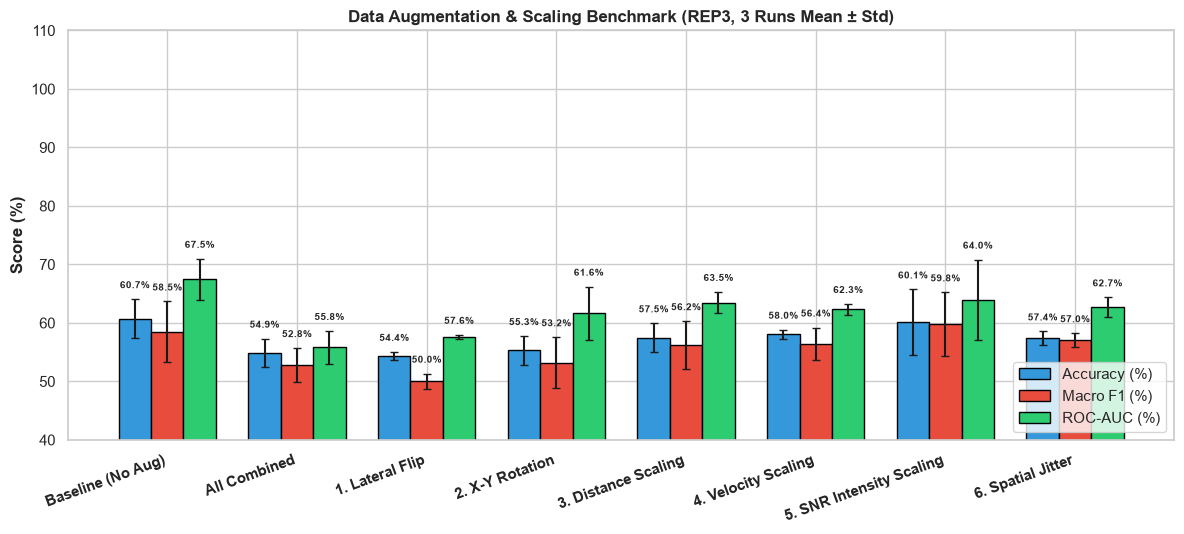

In [19]:
# Cell 6: Performance Summary DataFrame & Comparative Bar Chart with Error Bars
records = []
for name, m in ablation_results.items():
    records.append({
        "Technique": name,
        "Accuracy (%)": f"{m['accuracy']*100:.2f}% ± {m['accuracy_std']*100:.2f}%",
        "Recall (%)": f"{m['recall']*100:.2f}% ± {m['recall_std']*100:.2f}%",
        "Precision (%)": f"{m['precision']*100:.2f}% ± {m['precision_std']*100:.2f}%",
        "Macro F1 (%)": f"{m['macro_f1']*100:.2f}% ± {m['macro_f1_std']*100:.2f}%",
        "ROC-AUC": f"{m['roc_auc']:.4f} ± {m['roc_auc_std']:.4f}"
    })

df_summary = pd.DataFrame(records)
print(f"=== Data Augmentation Benchmark Summary ({REPRESENTATION.upper()}, {NUM_RUNS} Runs Mean ± Std) ===")
print(df_summary.to_string(index=False))

# Plot Bar Chart with Error Bars (Mean ± Std)
names = list(ablation_results.keys())
acc_m = [ablation_results[n]["accuracy"] * 100 for n in names]
acc_s = [ablation_results[n]["accuracy_std"] * 100 for n in names]
f1_m = [ablation_results[n]["macro_f1"] * 100 for n in names]
f1_s = [ablation_results[n]["macro_f1_std"] * 100 for n in names]
auc_m = [ablation_results[n]["roc_auc"] * 100 for n in names]
auc_s = [ablation_results[n]["roc_auc_std"] * 100 for n in names]

fig, ax = plt.subplots(figsize=(12, 5.5), dpi=100)
x = np.arange(len(names))
w = 0.25

b1 = ax.bar(x - w, acc_m, yerr=acc_s, width=w, label="Accuracy (%)", color="#3498db", edgecolor="black", capsize=3)
b2 = ax.bar(x, f1_m, yerr=f1_s, width=w, label="Macro F1 (%)", color="#e74c3c", edgecolor="black", capsize=3)
b3 = ax.bar(x + w, auc_m, yerr=auc_s, width=w, label="ROC-AUC (%)", color="#2ecc71", edgecolor="black", capsize=3)

ax.set_xticks(x)
ax.set_xticklabels(names, rotation=20, ha="right", fontweight="bold")
ax.set_ylabel("Score (%)", fontweight="bold")
ax.set_ylim([40, 110])
ax.set_title(f"Data Augmentation & Scaling Benchmark ({REPRESENTATION.upper()}, {NUM_RUNS} Runs Mean ± Std)", fontweight="bold")
ax.legend(loc="lower right")

for bars, stds in zip((b1, b2, b3), (acc_s, f1_s, auc_s)):
    for bar, std in zip(bars, stds):
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., h + std + 1.5, f"{h:.1f}%", ha="center", va="bottom", fontsize=7.5, fontweight="bold")

plt.tight_layout()
plt.show()
